# Lorenz-96 with a nonlinear observation operator

Lorenz-96, $d = 40$, $N_e = 20$, $h(x) = \arctan(x)$ applied to every 2nd variable
($50\,\%$ coverage), $\sigma_{\rm obs} = 0.05$, analyses every $\Delta t_{\rm obs} = 0.2$
(a 24-hour cycle). The initial ensemble is climatological: $K$ states drawn from a long free
run, so the ensemble mean starts about one climatological standard deviation ($3.67$) from
the truth. Eighty cycles are run and cycles 40-79 are scored, the first forty being the
climatological transient. Hyperparameters were tuned on seeds 100-119 and the methods are
scored on seeds 0-39.

| | linear experiment | here |
|---|---|---|
| operator | $h(x) = x$ | $h(x) = \arctan(x)$ |
| $\sigma_{\rm obs}$ | $0.1$ | $0.05$ |
| coverage | $25\,\%$ | $50\,\%$ |
| initial ensemble | truth $+\,0.5\,\mathcal{N}(0,I)$ | climatology |
| likelihood | $\mathbf{R}$ fixed | annealed, $\kappa = 0.025$ |

For a saturating operator the informative quantity is the equivalent state-space error
$\sigma_{\rm obs}/h'(x) = \sigma_{\rm obs}(1 + x^2)$. Lorenz-96 at $F = 8$ spends $27\,\%$ of
its time at $|x| \ge 5$, where $\sigma_{\rm obs} = 0.1$ would give an equivalent error of
$2.6$; at $\sigma_{\rm obs} = 0.05$ the equivalent error stays below the climatological
spread, and the coverage is doubled.

| method | treatment of $h$ |
|---|---|
| LETKF | ensemble covariances of $h(\mathbf{x}^k)$, one statistical linearization per analysis |
| RML-3DVar | Gauss-Newton, relinearized at each iterate |
| CI-EnSF | $h$ and $h'$ evaluated at each member's own state at every step of the reverse transport |

For a given seed all three share the truth trajectory, the observation network, the
observation-noise realization, the ensemble size and the initial ensemble. A run is a failure
if it becomes non-finite (*overflow*) or if its scored RMSE exceeds half the climatological
standard deviation (*filter divergence*).

**Produces** Table 2 and Figure 3 of the manuscript. The selected hyperparameters are
hard-coded in section 6; no sweep is re-run. Set `RUN_SIMULATION = False` to rebuild the
table and the figure from `arctan24h_cold_cache.npz`.

## 1. Configuration

In [1]:
import numpy as np, time, json
import matplotlib
import matplotlib.pyplot as plt

# ---------------- model
D            = 40          # state dimension
F_FORCING    = 8.0         # Lorenz-96 forcing
DT_TRUTH     = 0.01        # integration step for the truth
DT_MODEL     = 0.02        # integration step for the forecast model (deliberately coarser)
DT_OBS       = 0.2         # analysis interval.  L96 at F=8 has a doubling time of 0.42,
                           # so this is half a doubling time -- the standard setting.
SPINUP_STEPS = 2000        # steps to reach the attractor before the truth run starts

# ---------------- observations
OBS_STRIDE   = 2           # observe every 2nd variable -> 50 % coverage
SIGMA_OBS    = 0.05        # observation error standard deviation, IN OBSERVATION
                           # SPACE.  The equivalent state-space error is
                           # sigma_obs/h'(x) = sigma_obs (1 + x^2); see the header.

# ---------------- ensemble
K            = 20          # ensemble members
COLD_START   = True        # the initial ensemble is drawn from the model CLIMATOLOGY, not
                           # from a perturbation of the truth: the filter begins a full
                           # climatological standard deviation away and has to find the
                           # truth on its own.  This is the difficulty this experiment adds.
CLIM_POOL_N  = 400         # states in the climatological pool
CLIM_GAP     = 100         # DT_TRUTH steps between pool states (1.0 time units, about two
                           # error-doubling times, so the members are effectively independent
                           # draws from the attractor)
CLIM_SEED    = 987654321   # the pool is a property of the MODEL, not of a seed

# ---------------- experiment
N_CYCLES     = 80          # 80, not 40: the climatological transient has to clear before
                           # any steady-state score means anything
SCORE_SKIP   = 0.5         # score cycles 40-79.  The transient clears by cycle ~30 for all
                           # three methods (measured out to 150 cycles), so this leaves a
                           # 10-cycle margin.  Fixed before any evaluation seed was run.
EVAL_SEEDS   = tuple(range(40))   # 40, not 10: what this experiment turns on is the
                                  # FAILURE RATE, which ten seeds cannot resolve
EPS_C        = 1e-6        # ridge added to B before its eigendecomposition
STD_FLOOR    = 1e-8

obs_idx  = np.arange(0, D, OBS_STRIDE)
obs_mask = np.zeros(D, bool); obs_mask[obs_idx] = True
Q        = obs_idx.size
R_DIAG   = np.full(Q, SIGMA_OBS**2)


### Recomputation switch

`RUN_SIMULATION = False` rebuilds the table and the figure from `arctan24h_cold_cache.npz`
without running a filter. The cache is written whenever `RUN_SIMULATION = True`.

In [2]:
import os, json
RUN_SIMULATION = False       # False -> load exp1_cache.npz and only redraw
CACHE = "arctan24h_cold_cache.npz"

def save_cache(**kw):
    # compressed: the JSON payloads are stored by numpy as UTF-32, four bytes per
    # character, so an uncompressed cache is several times larger than it needs to be.
    np.savez_compressed(CACHE, **{k: (v if isinstance(v, np.ndarray) else np.array(json.dumps(v)))
                                  for k, v in kw.items()})

def load_cache():
    z = np.load(CACHE, allow_pickle=False)
    return {k: (json.loads(str(z[k])) if z[k].dtype.kind in "US" else z[k]) for k in z.files}

if not RUN_SIMULATION and not os.path.exists(CACHE):
    raise SystemExit("RUN_SIMULATION = False but %s is missing; run once with True." % CACHE)

## 2. Model and observation operator

Lorenz-96, $\dot x_i = (x_{i+1}-x_{i-2})x_{i-1} - x_i + F$, integrated with RK4. The observation operator is $h(x) = \arctan(x)$ on `obs_idx`, with
$h'(x) = 1/(1+x^2)$.

In [3]:
def l96_rhs(x):
    return (np.roll(x, -1, -1) - np.roll(x, 2, -1))*np.roll(x, 1, -1) - x + F_FORCING

def rk4(x, dt, steps):
    for _ in range(steps):
        k1 = l96_rhs(x); k2 = l96_rhs(x + 0.5*dt*k1)
        k3 = l96_rhs(x + 0.5*dt*k2); k4 = l96_rhs(x + dt*k3)
        x = x + (dt/6.0)*(k1 + 2*k2 + 2*k3 + k4)
    return x

# ---------------- the climatological initial ensemble
_POOL = None
def clim_pool():
    """A long free run of the model, sampled at intervals long enough to decorrelate."""
    global _POOL
    if _POOL is None:
        r = np.random.default_rng(CLIM_SEED)
        x = rk4(r.normal(scale=3.0, size=D), DT_TRUTH, SPINUP_STEPS)
        P = np.empty((CLIM_POOL_N, D))
        for i in range(CLIM_POOL_N):
            P[i] = x; x = rk4(x, DT_TRUTH, CLIM_GAP)
        _POOL = P
    return _POOL

def climatological_ensemble(rng):
    """K members drawn without replacement from the pool.  Not re-centred on anything: the
    mean is the climatological mean and the spread is the climatological spread."""
    P = clim_pool()
    return P[rng.choice(len(P), size=K, replace=False)].copy()

M_op     = lambda v: np.arctan(v)          # saturating observation operator
M_prime  = lambda v: 1.0/(1.0 + v**2)      # h'(x) -> 0 as |x| grows

def make_truth(seed, n_cycles):
    """Truth trajectory and initial ensemble.  The rng is returned and reused so that the
    observation noise and every filter's own draws come from ONE stream per seed."""
    rng = np.random.default_rng(seed)
    x = rk4(rng.normal(scale=3.0, size=D), DT_TRUTH, SPINUP_STEPS)
    T = np.empty((n_cycles, D))
    for n in range(n_cycles):
        T[n] = x
        x = rk4(x, DT_TRUTH, int(round(DT_OBS/DT_TRUTH)))
    X0 = climatological_ensemble(rng)
    return T, X0, rng

# The climatological standard deviation sets the filter-divergence threshold, so it is
# measured here rather than hard-coded: a 400-cycle truth run of the model.
_T, _, _ = make_truth(0, 400)
CLIM_STD  = float(_T.std())     # 3.668
FAIL_RMSE = 0.5*CLIM_STD        # filter-divergence threshold, 1.834

## 3. Localization and the background-error covariance

Notation follows the manuscript. $\mathbf{C}$ is the localized correlation matrix of the
standardized ensemble, Eq. (17):

$$\mathbf{C} = \frac{1}{1+\varepsilon}\Big[\mathbf{C}_{\rm loc}\circ
\frac{\mathbf{A}\mathbf{A}^\top}{N_e-1} + \varepsilon\mathbf{I}\Big],
\qquad \varepsilon = 10^{-6},$$

with $\mathbf{A}$ the matrix of standardized anomalies, so $\mathbf{C}$ has unit diagonal.
The physical-space covariance of Eq. (19) is $\mathbf{B}^f = \mathbf{D}\mathbf{C}\mathbf{D}$
with $\mathbf{D} = \mathrm{diag}(\sigma^f)$. In the code these are `Cm` and `Bf`.

$\mathbf{C}_{\rm loc}$ here is the **indicator** of the Gaspari-Cohn support, 1 inside and 0
outside, with the half-support convention: $\rho_{\rm GC}(r/L)$ is zero for $r \ge 2L$, so
`L_loc` is a scale and the support ends at $2\,$`L_loc`. An indicator taper is not positive
semidefinite — its smallest eigenvalue is about $-2.4$ at $L = 3$ — so $\varepsilon$ alone
does not make $\mathbf{C}$ usable and `build_C` clips the eigenvalues at zero. The SQG
experiments use Gaspari-Cohn values instead, which are positive semidefinite.

RML-3DVar and CI-EnSF build the same $\mathbf{C}$.

In [4]:
def rho_gc(rr):
    """Gaspari-Cohn, compactly supported on rr < 2."""
    rr = np.abs(np.asarray(rr, float)); out = np.zeros_like(rr)
    n = rr <= 1; x = rr[n]; out[n] = 1 - (5/3)*x**2 + (5/8)*x**3 + 0.5*x**4 - 0.25*x**5
    f = (rr > 1) & (rr < 2); x = rr[f]
    out[f] = 4 - 5*x + (5/3)*x**2 + (5/8)*x**3 - 0.5*x**4 + x**5/12 - 2/(3*x)
    return out

DIST = np.minimum(np.abs(np.arange(D)[:,None] - np.arange(D)[None,:]),
                  D - np.abs(np.arange(D)[:,None] - np.arange(D)[None,:]))

_TAPER = {}
def taper_matrix(L_loc):
    """Indicator taper at scale L_loc (support ends at 2*L_loc)."""
    key = float(L_loc)
    if key not in _TAPER:
        _TAPER[key] = (rho_gc(DIST/float(L_loc)) > 0).astype(float)
    return _TAPER[key]

def build_C(U, L_loc):
    """Localized correlation of the standardized ensemble U (K, d), and a square root.

    The eigenvalue clip is not optional: running the transport with the raw, unclipped
    Schur product loses every seed within a few cycles, because the indicator taper is not
    positive semidefinite (its smallest eigenvalue is about -2.4 at L_loc = 3)."""
    A  = U - U.mean(0)
    P  = taper_matrix(L_loc)*((A.T @ A)/(K - 1))
    Cm = (P + EPS_C*np.eye(D))/(1.0 + EPS_C)
    lam, QB = np.linalg.eigh(0.5*(Cm + Cm.T))
    lam = np.maximum(lam, 0.0)
    return (QB*lam) @ QB.T, QB*np.sqrt(lam)

def standardize(Xf):
    shift = Xf.mean(0)
    std   = np.maximum(Xf.std(0, ddof=1), STD_FLOOR)
    return shift, std, (Xf - shift)/std


## 4. The three analysis schemes

All three have the signature `analyze(Xf, y, rng, **hyper) -> Xa`, both `(K, d)` in physical
units, so the cycling driver is shared.

### 4.1 LETKF
Ensemble transform solved in the $K$-dimensional ensemble subspace with domain localization:
for each grid point $j$, observations inside the GC support of $j$ are assimilated, weighted
by $\rho_{\rm GC}$. No explicit $d\times d$ covariance is formed.

In [5]:
def letkf(Xf, y, rng, L_loc=3.0, inflation=1.0, **_):
    xbar = Xf.mean(0); Xb = Xf - xbar
    if inflation != 1.0: Xb = Xb*inflation
    hx = M_op(Xf[:, obs_idx] if inflation == 1.0 else (xbar + Xb)[:, obs_idx])
    Yb = hx - hx.mean(0); d = y - hx.mean(0)
    Xa = np.empty_like(Xf)
    for j in range(D):
        w = rho_gc(DIST[j, obs_idx]/L_loc)
        sel = w > 0
        if not sel.any(): Xa[:, j] = xbar[j] + Xb[:, j]; continue
        Yl = Yb[:, sel]; inv = w[sel]/R_DIAG[sel]
        A = (K - 1)*np.eye(K) + (Yl*inv) @ Yl.T
        lam, Qm = np.linalg.eigh(0.5*(A + A.T)); lam = np.maximum(lam, 1e-12)
        Pa = (Qm/lam) @ Qm.T
        wa = Pa @ ((Yl*inv) @ d[sel])
        W  = (Qm*np.sqrt((K - 1)/lam)) @ Qm.T
        Xa[:, j] = xbar[j] + Xb[:, j] @ (wa[:, None] + W)
    return Xa

### 4.2 RML-3DVar (ensemble 3D-Var)

Each member minimizes its own randomized cost. For a nonlinear $h$ the cost is not quadratic,
so it is minimized by Gauss-Newton with $\mathbf{H}_i = \mathrm{diag}\,h'(\mathbf{x}_i)$
relinearized at each iterate:
$$\mathbf{x}_{i+1} = \mathbf{x}^k + \gamma\mathbf{B}^f\mathbf{H}_i^\top
(\gamma\mathbf{H}_i\mathbf{B}^f\mathbf{H}_i^\top + \mathbf{R})^{-1}
\big[\mathbf{y}^k - h(\mathbf{x}_i) + \mathbf{H}_i(\mathbf{x}_i - \mathbf{x}^k)\big].$$
Five iterations are used. For a linear $h$ this converges in one step to the closed form.

In [6]:
def rml_3dvar(Xf, y, rng, gamma=1.0, L_loc=3.0, n_iter=5, tol=1e-6, **_):
    """RML / ensemble 3D-Var solved by Gauss-Newton.

    Each member minimizes its own randomized cost

        J(x) = .5 (x-x^k)' (gamma B)^-1 (x-x^k) + .5 (y^k-h(x))' R^-1 (y^k-h(x)),

    which is NOT quadratic for a nonlinear h, so there is no closed form.  Gauss-Newton
    relinearizes AT EACH ITERATE, H_i = diag(h'(x_i)), and solves the linearized problem in
    incremental form:

        x_{i+1} = x^k + gamma B H_i' (gamma H_i B H_i' + R)^-1
                        [ y^k - h(x_i) + H_i (x_i - x^k) ].

    For a LINEAR h the cost is already quadratic and this converges in one step exactly, so
    it reduces to the closed-form update of the linear experiment -- checked there to
    machine precision.  For arctan it converges geometrically: successive iterates differ by
    2e-2, 4e-3, 6e-4, 6e-5 at n_iter = 2, 3, 5, 8.

    An earlier version linearized once, at the ensemble mean.  Iterating to convergence
    improves accuracy on surviving seeds by 44 % but does NOT change the failure count, which
    is what this experiment turns on."""
    shift, std, U = standardize(Xf)
    Cm, _ = build_C(U, L_loc)
    Bf  = (std[:, None]*Cm)*std[None, :]
    Bf_oo = Bf[np.ix_(obs_idx, obs_idx)]; Bf_xo = Bf[:, obs_idx]
    yk  = y + rng.normal(scale=np.sqrt(R_DIAG), size=(K, Q))
    Xa  = Xf.copy()
    for k in range(K):
        xk = Xf[k]; xi = xk.copy()
        for _ in range(n_iter):
            Hi  = M_prime(xi[obs_idx])
            w   = yk[k] - M_op(xi[obs_idx]) + Hi*(xi[obs_idx] - xk[obs_idx])
            S   = gamma*(Bf_oo*np.outer(Hi, Hi)) + np.diag(R_DIAG)
            new = xk + gamma*((Bf_xo*Hi) @ np.linalg.solve(S, w))
            if np.abs(new - xi).max() < tol: xi = new; break
            xi = new
        Xa[k] = xi
    return Xa

### 4.3 CI-EnSF

Conditioned on the standardized member $\mathbf{u}_i$ the transition kernel is Eq. (26),
$$\mathbf{z}_t \mid \mathbf{u}_i \sim
\mathcal{N}\big((1-t)\mathbf{u}_i,\ c(t)\mathbf{C}\big),\qquad c(t) = (1-t)^2\gamma + t,$$
so the covariance stays a scalar multiple of $\mathbf{C}$ and the covariance-weighted
forecast score is Eq. (30),
$$\mathbf{C}\,\mathbf{s}^f_{t,i}(\mathbf{z})
= -\frac{\mathbf{z} - (1-t)\mathbf{u}_i}{c(t)},$$
i.e. $\mathbf{C}$ cancels from the prior transport and is never solved with. It remains in
the likelihood transport of Eq. (37), weighted by $w(t) = 1-t$. Perturbed observations are
used, one set per member, drawn with the same
$\mathbf{R}_{\rm eff}$ the likelihood uses. $h$ and $h'$ are evaluated at each member's
current state.

In [7]:
# --- the innovation-consistency controller for gamma -------------------------------------
# gamma sets the prior width; a FIXED gamma cannot react when the forecast ensemble becomes
# over- or under-confident relative to the actual innovations.  The controller below is to
# CI-EnSF what multiplicative inflation is to the LETKF -- part of the standard
# configuration, not an optional extra -- so it is exposed as a tuning option (`ctrl`)
# rather than left off.  It uses only y and the forecast, never the truth.
W_SMOOTH, P_GAIN = 0.3, 0.5
GAMMA_LO, GAMMA_HI = 0.05, 0.15

def innovation_ratio(Xf, y):
    """rho = sum d^2 / sum[(1 + 1/K) s_f^2 + r].  Target 1.  The (1 + 1/K) is the
    finite-ensemble correction; without it rho is biased high by 5 % at K = 20."""
    hx = M_op(Xf[:, obs_idx]); d = y - hx.mean(0)
    return float(d @ d / np.sum((1.0 + 1.0/K)*hx.var(0, ddof=1) + R_DIAG))

def update_gamma(gamma, rho_s, ctrl="on"):
    """on : gamma <- clip(gamma * rho_s**P_GAIN, GAMMA_LO, GAMMA_HI).  A single
            multiplicative response with no trigger threshold and no decay constant: the
            smoothed ratio rho_s is already the only quantity the controller needs, and
            rho_s < 1 shrinks gamma by the same law that rho_s > 1 grows it.
       off: no control, gamma stays at its initial value."""
    if ctrl == "off": return gamma
    return float(min(max(gamma*rho_s**P_GAIN, GAMMA_LO), GAMMA_HI))


def anneal_R(d_innov, kappa):
    """Likelihood annealing: r_eff = max(R, kappa * mean(d^2)).

    E[d d'] = H P^f H' + R, so this turns the likelihood transport's R^-1 into
    (H P^f H' + R)^-1 -- the LETKF's denominator -- whenever the background is far more
    uncertain than the observations, which is the situation at a climatological start.  It
    is self-annealing: the innovations shrink as the filter converges and the max() returns
    to R with no external schedule.

    The SAME r_eff must be used for the perturbed observations inside the analysis, or the
    randomization is inconsistent with the likelihood and the analysis under-disperses.

    This also relieves the reverse ODE's stiffness directly, since the step requirement
    scales as <(sigma_o h')^2 / r>, which is why N_t = 400 suffices here with annealing on;
    adaptivity_2x2.ipynb separates the two effects."""
    if kappa <= 0: return R_DIAG
    return np.maximum(R_DIAG, kappa*float(np.mean(d_innov**2)))


def cvt_ensf(Xf, y, rng, gamma=0.1, L_loc=4.0, n_steps=400, t_stop=0.1, r_eff=None, **_):
    shift, std, U = standardize(Xf)
    Cm, Lm = build_C(U, L_loc)
    off_o, std_o = shift[obs_idx], std[obs_idx]
    r_eff = R_DIAG if r_eff is None else r_eff
    yk = y + rng.normal(scale=np.sqrt(r_eff), size=(K, Q))   # same r_eff as the likelihood
    dt = (1.0 - t_stop)/n_steps
    z  = rng.standard_normal((K, D)) @ Lm.T     # terminal law N(0, B), not N(0, I)
    for n in range(n_steps):
        t  = 1.0 - (n + 1)*dt
        c  = (1.0 - t)**2*gamma + t
        bb = 1.0/(1.0 - t); s2 = (1.0 + t)/(1.0 - t)
        Cs = -(z - (1.0 - t)*U)/c               # B cancels here
        xs  = std_o*z[:, obs_idx] + off_o
        lik = np.zeros_like(z)
        lik[:, obs_idx] = -(std_o*M_prime(xs))*(M_op(xs) - yk)/r_eff
        Cs = Cs + (1.0 - t)*(lik @ Cm)          # B acts here, spreading information
        z  = z - dt*(-bb*z - 0.5*s2*Cs)
        if not np.isfinite(z).all():
            raise FloatingPointError("CI-EnSF diverged at step %d (t=%.4f)" % (n, t))
    return std*z + shift

METHODS = {"LETKF": letkf, "RML-3DVar": rml_3dvar, "CI-EnSF": cvt_ensf}

## 5. Cycling driver and scoring

Shared by all three methods. Overflow and filter divergence are recorded separately, and the
observed / unobserved error split is kept for every run.

In [8]:
def run_cycles(fn, kw, seed, n_cycles=N_CYCLES):
    """Returns (hist, status) with hist columns (rmse_obs, rmse_unobs, rmse_all, spread)."""
    T, X, rng = make_truth(seed, n_cycles)
    hist, status = [], "ok"
    kw = dict(kw)
    ctrl  = kw.pop("ctrl", None)                   # CI-EnSF only
    kappa = kw.pop("kappa", None)                  # CI-EnSF only
    gamma, rho_s = kw.get("gamma", None), 1.0
    for n in range(n_cycles):
        y = M_op(T[n][obs_idx]) + rng.normal(scale=SIGMA_OBS, size=Q)
        if ctrl is not None and ctrl != "off":
            # innovation_ratio is given the TRUE R, never r_eff: feeding it the annealed
            # value would drive rho to 1 by construction and blind the controller
            rho_s = (1 - W_SMOOTH)*rho_s + W_SMOOTH*innovation_ratio(X, y)
            gamma = update_gamma(gamma, rho_s, ctrl)
            kw["gamma"] = gamma
        if kappa is not None:
            kw["r_eff"] = anneal_R(y - M_op(X[:, obs_idx]).mean(0), kappa)
        try:
            X = fn(X, y, rng, **kw)
        except (FloatingPointError, np.linalg.LinAlgError):
            status = "overflow"; break
        e = X.mean(0) - T[n]
        hist.append((np.sqrt((e[obs_mask]**2).mean()), np.sqrt((e[~obs_mask]**2).mean()),
                     np.sqrt((e**2).mean()), float(np.sqrt(X.var(0, ddof=1).mean()))))
        X = rk4(X, DT_MODEL, int(round(DT_OBS/DT_MODEL)))
        if not np.isfinite(X).all(): status = "overflow"; break
    h = np.array(hist) if hist else np.zeros((0, 4))
    i0 = int(SCORE_SKIP*n_cycles)
    if status == "ok" and (len(h) < n_cycles or h[i0:, 2].mean() > FAIL_RMSE):
        status = "divergence"
    return h, status

def summarise(fn, kw, seeds, n_cycles=N_CYCLES):
    """Per-seed scores.  Values are kept for failed seeds too, and flagged, so that a method
    is never flattered by silently dropping the seeds it failed on."""
    out = []
    for s in seeds:
        h, st = run_cycles(fn, kw, s, n_cycles)
        i0 = int(SCORE_SKIP*n_cycles)
        if len(h) > i0:
            # The per-cycle history of EVERY seed is kept: the figure reports the median
            # and interquartile range across realisations, which one seed cannot convey.
            #
            # spread/RMSE is aggregated in the SQUARE and only then divided.  The
            # spread-skill identity E[spread^2] = (K/(K+1)) E[error^2] is a relation between
            # second moments, so sqrt(mean s^2)/sqrt(mean r^2) is what the reference
            # sqrt(K/(K+1)) applies to; a mean of per-cycle ratios is biased high, returning
            # 0.994 against the reference 0.976 at d = 40 on an ensemble calibrated by
            # construction, by an amount that depends on d.
            out.append(dict(seed=s, status=st, hist=h.tolist(),
                            rmse=h[i0:,2].mean(), obs=h[i0:,0].mean(),
                            unobs=h[i0:,1].mean(),
                            sprms=float(np.sqrt((h[i0:,3]**2).mean()
                                              / (h[i0:,2]**2).mean()))))
        else:
            out.append(dict(seed=s, status=st, hist=h.tolist(),
                            rmse=np.inf, obs=np.inf, unobs=np.inf, sprms=np.nan))
    return out


## 6. Selected hyperparameters

Every value below is a literal, selected on seeds 100-119. The search is not re-run here.

| | selected value |
|---|---|
| LETKF | $L = 2$, inflation $1.15$ |
| RML-3DVar | $\gamma = 0.02$, $L = 1.5$, 5 Gauss-Newton iterations |
| CI-EnSF | $\gamma_0 = 0.1$, $L = 1.5$, $N_t = 400$, $\kappa = 0.025$, controller on |
| $\gamma$ controller | $w_{\rm EMA} = 0.3$, $p = 1/2$, $\gamma \in [0.05,\, 0.15]$ |
| localization ridge | $\varepsilon = 10^{-6}$ |

The controller update law is
$\gamma \leftarrow \mathrm{clip}(\gamma\,\rho_s^{1/2}, \gamma_{\rm lo}, \gamma_{\rm hi})$.
$\gamma_0$, $L$ and $\kappa$ were selected under the earlier two-sided controller and are
carried over unchanged.

In [9]:
# Selected hyperparameters -- literals; section 6 says where each came from.  The gamma
# controller's own constants are hard-coded in section 4.3 (W_SMOOTH = 0.3, P_GAIN = 0.5,
# GAMMA_LO = 0.05, GAMMA_HI = 0.15) and the localization ridge in section 1 (EPS_C = 1e-6).
TUNED = {"LETKF":     dict(L_loc=2.0,  inflation=1.15),
         "RML-3DVar": dict(gamma=0.02, L_loc=1.5, n_iter=5),
         "CI-EnSF":   dict(gamma=0.1,  L_loc=1.5, ctrl="on", n_steps=400, kappa=0.025)}

## 7. The 40-seed evaluation run

Forty evaluation seeds (0-39), disjoint from the tuning seeds, each method at the setting
above: 80 analysis cycles from a climatological ensemble, scored over cycles 40-79.

In [10]:
if RUN_SIMULATION:
    RESULTS = {}
    for name in METHODS:
        t0 = time.time()
        RESULTS[name] = summarise(METHODS[name], TUNED[name], EVAL_SEEDS)
        print("%-11s done  [%.0f s]" % (name, time.time() - t0))
else:
    RESULTS = load_cache()["results"]
    print("loaded %d methods from cache" % len(RESULTS))

loaded 3 methods from cache


In [11]:
def table(results):
    """Five metrics, reporting the survivor-conditional and the all-seed view side by side.

        survived      seeds completed without overflow or filter divergence
        RMSE (surv)   mean RMSE over the surviving seeds only
        sp/rms (surv) ensemble spread over RMSE, survivors only; the ideal value is
                      sqrt(K/(K+1)) = 0.976 for K = 20, not 1
        RMSE (all)    mean RMSE over every seed, failures included at their actual score
        worst         the single worst seed

    Both means are reported deliberately.  A survivor-only mean flatters whichever method
    discards the most difficult seeds, because the score improves precisely by removing the
    hard cases; an all-seed mean conflates how OFTEN a method fails with how BADLY.  Neither
    is wrong, and side by side they cannot mislead.

    A run ending before the scoring window opens has no RMSE of its own and is given the
    filter-divergence threshold, the smallest value consistent with having lost the truth.
    That case does not arise here -- every failed run reached the window -- but it is stated
    because the all-seed mean would otherwise depend on the choice silently.
    """
    rows = []
    for name, r in results.items():
        allr = np.array([x["rmse"] if np.isfinite(x["rmse"]) else FAIL_RMSE for x in r])
        ok   = [x for x in r if x["status"] == "ok"]
        rmo  = np.array([x["rmse"] for x in ok]) if ok else np.array([np.nan])
        rows.append(dict(
            method=name, n_ok=len(ok), n=len(r),
            overflow=sum(x["status"] == "overflow" for x in r),
            divergence=sum(x["status"] == "divergence" for x in r),
            rmse_surv=float(rmo.mean()),
            sprms=float(np.nanmean([x["sprms"] for x in ok])) if ok else float("nan"),
            rmse_all=float(allr.mean()), worst=float(allr.max()),
            # observed/unobserved are kept for the text; they are averaged over the
            # SURVIVING seeds, a failed seed having no finite error to contribute.  The
            # ratio of the two is not stored: over all seeds it evaluated to inf/inf.
            obs=float(np.mean([x["obs"] for x in ok])) if ok else float("nan"),
            unobs=float(np.mean([x["unobs"] for x in ok])) if ok else float("nan")))
    return rows

ROWS = table(RESULTS)

if RUN_SIMULATION:
    save_cache(tuned=TUNED, results=RESULTS, rows=ROWS)

## 8. Table 2

Five columns: method, stable realizations, RMSE over the stable realizations, spread/RMSE,
and RMSE over all 40 realizations with failures carried at their actual score. Spread/RMSE is
aggregated in the square, $\sqrt{\overline{s^2}}/\sqrt{\overline{r^2}}$, so the reference
value is $\sqrt{K/(K+1)} = 0.976$.

In [12]:
# Row order follows the manuscript: the method under test first, then the two baselines.
ORDER = ["CI-EnSF", "LETKF", "RML-3DVar"]

def latex_table(rows):
    """Table 2 exactly as the manuscript sets it: five columns, no grouped header.

    `worst` is still computed and kept in arctan24h_cold_results.json, but it is not a
    column of Table 2 and is not printed here."""
    by = {r["method"]: r for r in rows}
    o = [r"\begin{tabular}{lcccc}", r"\toprule",
         r"Method & Stable realizations & RMSE (stable) & Spread/RMSE & RMSE (all) \\",
         r"\midrule"]
    for m in ORDER:
        r = by[m]
        o.append("%s & %d/%d & %.4f & %.2f & %.4f \\\\"
                 % (r["method"], r["n_ok"], r["n"], r["rmse_surv"], r["sprms"],
                    r["rmse_all"]))
    o += [r"\bottomrule", r"\end{tabular}"]
    return "\n".join(o)

print(latex_table(ROWS))
print()
for r in ROWS:
    if r["n_ok"] < r["n"]:
        print("%% %s: %d of %d seeds failed (%d overflow, %d filter divergence)."
              % (r["method"], r["n"]-r["n_ok"], r["n"], r["overflow"], r["divergence"]))
json.dump({"tuned": {k: {kk: (vv if isinstance(vv, str) else float(vv))
                         for kk, vv in v.items()} for k, v in TUNED.items()},
           "rows": ROWS,
           "per_seed": {k: [dict(status=x["status"],
                                 **{kk: float(x[kk])
                                    for kk in ("seed","rmse","obs","unobs","sprms")})
                             for x in v] for k, v in RESULTS.items()}},
          open("arctan24h_cold_results.json", "w"), indent=1)

\begin{tabular}{lcccc}
\toprule
Method & Stable realizations & RMSE (stable) & Spread/RMSE & RMSE (all) \\
\midrule
CI-EnSF & 40/40 & 0.3959 & 1.02 & 0.3959 \\
LETKF & 29/40 & 0.5315 & 1.19 & 1.1542 \\
RML-3DVar & 37/40 & 1.2186 & 0.98 & 1.2831 \\
\bottomrule
\end{tabular}

% LETKF: 11 of 40 seeds failed (7 overflow, 4 filter divergence).
% RML-3DVar: 3 of 40 seeds failed (0 overflow, 3 filter divergence).


## 9. Figure 3

(a) median analysis RMSE across the 40 seeds with the interquartile range; (b) the same for
the unobserved / observed RMSE ratio.

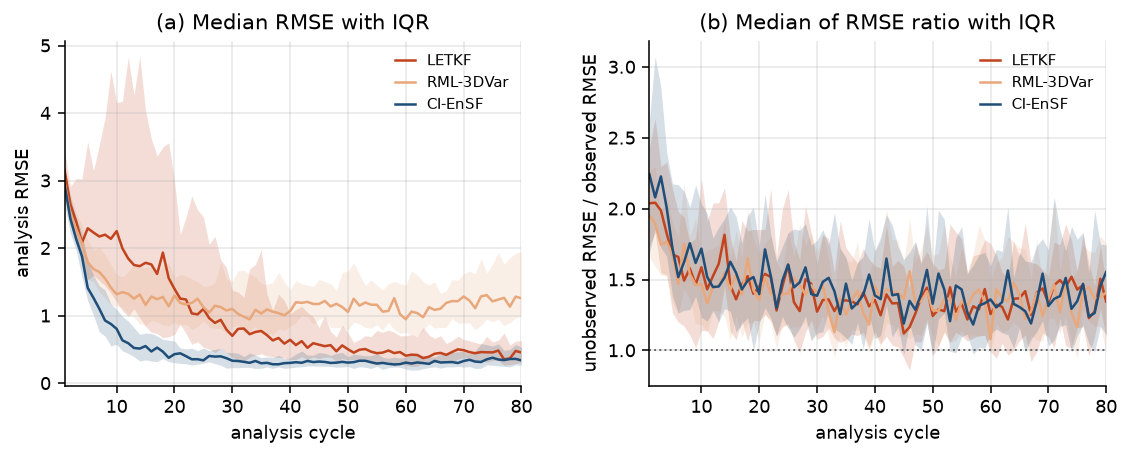

In [13]:
plt.rcParams.update({"font.size":9,"axes.grid":True,"grid.alpha":.3,"legend.frameon":False,
                     "axes.spines.top":False,"axes.spines.right":False,"figure.dpi":140,
                     "savefig.bbox":"tight","lines.linewidth":1.3})
COL = {"LETKF":"#c1441e","RML-3DVar":"#e8a87c","CI-EnSF":"#1f4e79"}
ORD = ["LETKF","RML-3DVar","CI-EnSF"]

def stack(method, col):
    """(n_seeds, N_CYCLES) of one history column, NaN-padded where a seed stopped early.

    Padding matters here in a way it does not in the Gaussian experiment: methods do fail on
    some seeds, and a failed seed contributes to the median only for the cycles it actually
    completed.  The median therefore thins out rather than jumping when a run ends."""
    A = np.full((len(RESULTS[method]), N_CYCLES), np.nan)
    for i, z in enumerate(RESULTS[method]):
        h = np.asarray(z["hist"], float)
        if len(h): A[i, :len(h)] = h[:, col]
    return A

fig, ax = plt.subplots(1, 2, figsize=(9.6, 3.2))
n = np.arange(1, N_CYCLES+1)

# (a) median across realisations with an interquartile envelope.  A single seed cannot show
#     whether a method is reliably better or merely lucky on that seed; the envelope can.
for m in ORD:
    A = stack(m, 2)                                   # column 2 = RMSE over all components
    q1, q2, q3 = (np.nanpercentile(A, p, axis=0) for p in (25, 50, 75))
    ax[0].fill_between(n, q1, q3, color=COL[m], alpha=.18, lw=0)
    ax[0].plot(n, q2, color=COL[m], label=m)
ax[0].set_xlim(1, N_CYCLES)
ax[0].set_xlabel("analysis cycle"); ax[0].set_ylabel("analysis RMSE")
ax[0].set_title("(a) Median RMSE with IQR")
ax[0].legend(fontsize=7.5, loc="upper right", handlelength=1.4)

# (b) the same construction applied to the unobserved/observed ratio, which says how far
#     observational information travels: the likelihood acts only at observed components, so
#     a ratio that stays of order one means B is carrying information into the rest.
for m in ORD:
    U, O = stack(m, 1), stack(m, 0)          # columns 1 and 0 = unobserved, observed
    Q = U/np.maximum(O, 1e-12)               # ratio per seed per cycle, then across seeds
    q1, q2, q3 = (np.nanpercentile(Q, p, axis=0) for p in (25, 50, 75))
    ax[1].fill_between(n, q1, q3, color=COL[m], alpha=.18, lw=0)
    ax[1].plot(n, q2, color=COL[m], label=m)
ax[1].axhline(1.0, color="0.4", ls=":", lw=1)
ax[1].set_xlim(1, N_CYCLES)
ax[1].set_xlabel("analysis cycle"); ax[1].set_ylabel("unobserved RMSE / observed RMSE")
ax[1].set_title("(b) Median of RMSE ratio with IQR")
ax[1].legend(fontsize=7.5, loc="upper right", handlelength=1.4)

fig.subplots_adjust(wspace=.28)
fig.savefig("arctan24h_cold_fig2.pdf"); plt.show()